# SAE "Analyse automatique de données" -- Notebook 1 : préparation des données

Dans ce notebook, vous devez :
1. Construire un dataframe avec les données brutes, contenant au moins une colonne pour l'avis textuel et une colonne pour la note correspondante ;
2. Nettoyer les données de ce dataframe (pour supprimer les éventuelles lignes en doublon, traiter les valeurs manquantes...) ;
3. Séparer le dataframe en 3 dataframes : un dataframe pour l'apprentissage, un dataframe pour la validation et un dataframe pour le test ;
4. Sauvegarder chacun des 3 dataframes dans un fichier.


## Modules python utilisés

In [103]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## 1. Construction du dataframe avec les données brutes

In [104]:
# Le fichier a été téléchargé sur https://huggingface.co/datasets/debojit01/fake-review-dataset/tree/main
fake_review_df = pd.read_csv("data/fake_reviews.csv")

# Affichage des headers
fake_review_df.columns.values.tolist()


['category', 'rating', 'label', 'text_']

## 2. Nettoyage des données

In [105]:
# CG = 0 et OR = 1
fake_review_df.loc[fake_review_df["label"] ==  "CG", "label"] = 0
fake_review_df.loc[fake_review_df["label"] ==  "OR", "label"] = 1

# Assure que la colonne est de type int
fake_review_df['label'] = fake_review_df['label'].astype(int)
print(fake_review_df)


                           category  rating  label  \
0                Home_and_Kitchen_5     5.0      0   
1                Home_and_Kitchen_5     5.0      0   
2                Home_and_Kitchen_5     5.0      0   
3                Home_and_Kitchen_5     1.0      0   
4                Home_and_Kitchen_5     5.0      0   
...                             ...     ...    ...   
40427  Clothing_Shoes_and_Jewelry_5     4.0      1   
40428  Clothing_Shoes_and_Jewelry_5     5.0      0   
40429  Clothing_Shoes_and_Jewelry_5     2.0      1   
40430  Clothing_Shoes_and_Jewelry_5     1.0      0   
40431  Clothing_Shoes_and_Jewelry_5     5.0      1   

                                                   text_  
0      Love this!  Well made, sturdy, and very comfor...  
1      love it, a great upgrade from the original.  I...  
2      This pillow saved my back. I love the look and...  
3      Missing information on how to use it, but it i...  
4      Very nice set. Good quality. We have had the s...

## 3. Séparation du dataframe en apprentissage, validation et test

Taille Train+Validation: 32345
Taille Test: 8087
Processeur remainder: passthrough
              precision    recall  f1-score   support

           0       0.91      0.91      0.91      4044
           1       0.91      0.91      0.91      4043

    accuracy                           0.91      8087
   macro avg       0.91      0.91      0.91      8087
weighted avg       0.91      0.91      0.91      8087



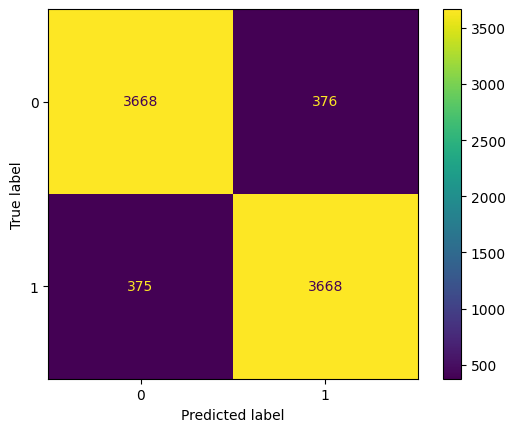

In [ ]:
X = fake_review_df[['category','text_','rating']]
y = fake_review_df['label']

X_train, X_test, y_train, y_test = train_test_split(X,y,
                                                    stratify=y, # Distribue les données de manière stratifiée = garantit que chaque sous ensemble à la même proportion de OR / CG
                                                    test_size=0.2,
                                                    random_state=42)

print(f"Taille Train+Validation: {len(X_train)}")
print(f"Taille Test: {len(X_test)}")

# On défini les différentes transformeurs 
processeur = ColumnTransformer(
    remainder='passthrough',
    transformers=[
        ('review', TfidfVectorizer(), 'text_'),
        ('category', OneHotEncoder(), ['category']),
        ('rating', StandardScaler(), ['rating'])
    ]
)

print(f"Processeur remainder: {processeur.remainder}")

# Mix des transformeurs et du classifieur
model = Pipeline([ 
    ('preprocessor', processeur),
    ('classifier',LinearSVC())
])


model.fit(X_train,y_train)

# Predictions
predictions = model.predict(X_test)
print(classification_report(y_test,predictions ))

disp = ConfusionMatrixDisplay(confusion_matrix(y_test,predictions),display_labels= model.classes_)
disp.plot()
plt.show()


## 4. Sauvegarde des dataframes dans des fichiers

In [108]:
def saveDataFrameToCsv(df: pd.DataFrame, filename: str, path: str):
    # Vérifier que le dossier existe
    os.makedirs(path,exist_ok=True)
    completePath = f"{path}/{filename}"
    try:
        df.to_csv(completePath)
        print(f"Dataframe sauvegardé à {completePath}")
    except:
        print(f"Dataframe: Erreur de sauvegarde du fichier {filename} dans le dossier {path}")

# Sauvegarde du dataframe filtrée
saveDataFrameToCsv(X, "x.csv","data/df_filtre")
saveDataFrameToCsv(y, "y.csv","data/df_filtre")

# Sauvegarde des données d'entrainements
saveDataFrameToCsv(X_train, "x_train.csv","data/train_test")
saveDataFrameToCsv(X_test, "x_test.csv","data/train_test")
saveDataFrameToCsv(y_train, "y_train.csv","data/train_test")
saveDataFrameToCsv(y_test, "y_test.csv","data/train_test")

Dataframe sauvegardé à data/df_filtre/x.csv
Dataframe sauvegardé à data/df_filtre/y.csv
Dataframe sauvegardé à data/train_test/x_train.csv
Dataframe sauvegardé à data/train_test/x_test.csv
Dataframe sauvegardé à data/train_test/y_train.csv
Dataframe sauvegardé à data/train_test/y_test.csv
